## Experiment 12 - Letter Box on Training Dataset Without Dropout

Full fine-tuning of an ImageNet-pretrained ResNet18 with:
with and without letterbox , augmentation, weight decay, ReduceLROnPlateau, Grad-CAM error analysis and without dropout

### Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.metrics import classification_report
from PIL import Image

PROJECT_DIR = Path.cwd().parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders,
    classify_unseen_folder
) 
from train import train_model
from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed,
)


### Config

In [21]:
SEED = 7
set_seed(SEED)

NUM_CLASSES = 8
BATCH_SIZE = 32

EPOCHS_FULL =150


BACKBONE_LR = 1e-4
HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4


# ============================================================
# GPU
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA/GPU is not available. "
        "Install a CUDA-enabled PyTorch version and make sure the NVIDIA driver is installed."
    )

DEVICE = torch.device("cuda")

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))

# Enable cuDNN optimizations for GPU training
torch.backends.cudnn.benchmark = True

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print("Device:", DEVICE)


Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


### Paths

In [22]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
TEST_DIR = PROJECT_DIR / "dataset" / "test"


UNSEEN_DIR = PROJECT_DIR / "dataset" / "neysan"

print("Train dir exists:", MERGED_TRAIN_DIR.exists())
print("Test dir exists:", TEST_DIR.exists())
print("Unseen dir exists:", UNSEEN_DIR.exists())


Train dir exists: True
Test dir exists: True
Unseen dir exists: True


### Transforms

Train transform adds augmentation (flip, rotation, color jitter, random erasing).
Val/test/unseen transform stays deterministic — same letterbox + ImageNet normalization used in every prior experiment, so results stay comparable.

In [23]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform1 = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

train_transform2 = transforms.Compose([

        transforms.Resize((224, 224)),

        transforms.RandomHorizontalFlip(p=0.5),

        transforms.RandomRotation(degrees=10),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )
    ])

eval_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


## Train Model With Letter Box in Train Transform

### Train / Val datasets

In [24]:
train_dataset, val_dataset, train_indices, val_indices, class_to_idx = \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=train_transform1,
        val_transform=eval_transform,
        test_size=0.2,
        seed=SEED,
    )

full_dataset = datasets.ImageFolder(MERGED_TRAIN_DIR)
class_names = full_dataset.classes

print("Train:", len(train_dataset), "Val:", len(val_dataset))
print("Classes:", class_names)


Train: 2712 Val: 679
Classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


### Test set (held out — used only at the very end)

In [25]:
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)
assert test_dataset.class_to_idx == class_to_idx, "Test set class mapping does not match train mapping!"

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print("Test set size:", len(test_dataset))


Test set size: 400


### Dataloaders

In [26]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True,
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 85
Val batches: 22


### Model — ResNet18, full fine-tuning

In [27]:
set_seed(SEED)

resnet_full = resnet18(weights=ResNet18_Weights.DEFAULT)

in_features = resnet_full.fc.in_features
resnet_full.fc = nn.Linear(in_features, NUM_CLASSES)

for param in resnet_full.parameters():
    param.requires_grad = True

resnet_full = resnet_full.to(DEVICE)


In [28]:
def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_total_parameters(model):
    return sum(p.numel() for p in model.parameters())

In [29]:
print("Trainable parameters:", count_trainable_parameters(resnet_full))
print("Total parameters:", count_total_parameters(resnet_full))

Trainable parameters: 11180616
Total parameters: 11180616


### Optimizer — per-group weight decay + two learning rates

Weight decay is applied to conv/linear weights but not to BatchNorm/bias parameters
(standard practice — decaying those tends to hurt, not help).

In [30]:
def split_decay(named_params):
    decay, no_decay = [], []
    for name, param in named_params:
        if not param.requires_grad:
            continue
        if param.ndim <= 1:  # BatchNorm weight/bias, Linear bias
            no_decay.append(param)
        else:
            decay.append(param)
    return decay, no_decay

backbone_named = [(n, p) for n, p in resnet_full.named_parameters() if not n.startswith("fc.")]
head_named = [(n, p) for n, p in resnet_full.named_parameters() if n.startswith("fc.")]

backbone_decay, backbone_no_decay = split_decay(backbone_named)
head_decay, head_no_decay = split_decay(head_named)

optimizer_full = torch.optim.Adam([
    {"params": backbone_decay,    "lr": BACKBONE_LR, "weight_decay": WEIGHT_DECAY},
    {"params": backbone_no_decay, "lr": BACKBONE_LR, "weight_decay": 0.0},
    {"params": head_decay,        "lr": HEAD_LR,     "weight_decay": WEIGHT_DECAY},
    {"params": head_no_decay,     "lr": HEAD_LR,     "weight_decay": 0.0},
])

def print_learning_rate_groups(optimizer):
    for i, group in enumerate(optimizer.param_groups):
        print(f"Group {i}: LR={group['lr']}, weight_decay={group['weight_decay']}, "
              f"parameters={sum(p.numel() for p in group['params'])}")

print_learning_rate_groups(optimizer_full)


Group 0: LR=0.0001, weight_decay=0.0001, parameters=11166912
Group 1: LR=0.0001, weight_decay=0.0, parameters=9600
Group 2: LR=0.0001, weight_decay=0.0001, parameters=4096
Group 3: LR=0.0001, weight_decay=0.0, parameters=8


### LR Scheduler — ReduceLROnPlateau

Monitors validation accuracy; halves the LR if it stalls for 3 epochs.
Scheduler patience (3) is set  so the LR gets a couple of chances to drop before training stops outright.

In [31]:
scheduler_full = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_full,
    mode="min",
    factor=0.03,
    patience=10,
    min_lr=1e-7,
)


### Loss

In [32]:
criterion_full = nn.CrossEntropyLoss()

### Config

In [33]:
config_full_letterbox = {
    "architecture": "ResNet18",
    "weights": "ImageNet pretrained",
    "strategy": "FinalModel_ResnetFull_Finetune",
    "num_classes": NUM_CLASSES,
    "input_size": (224, 224),
    "normalization": "ImageNet",
    "train transform": ["letterbox","hflip", "rotation10"],
    "optimizer": "Adam",
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "ReduceLROnPlateau(mode=max, factor=0.03, patience=10)",
    "seed": SEED,
    "trainable_layers": "all",
}


### Train

In [35]:
history_full_letterbox, best_val_acc_full_letterbox = train_model(
    model=resnet_full,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_full,
    optimizer=optimizer_full,
    device=DEVICE,
    epochs=EPOCHS_FULL,
    model_name="resnet18_full_finetuning_letterbox",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_full_letterbox,
    scheduler=scheduler_full,
    early_stopping=True,
    patience=75,
    min_delta=0.001,
)

print("Best validation accuracy:", best_val_acc_full_letterbox)


Epoch [1/150] Train Loss: 0.1372 --- Train Acc: 0.9620 --- Val Loss: 0.1389 --- Val Acc: 0.9543 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/150] Train Loss: 0.0748 --- Train Acc: 0.9812 --- Val Loss: 0.1312 --- Val Acc: 0.9588 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/150] Train Loss: 0.0598 --- Train Acc: 0.9834 --- Val Loss: 0.1404 --- Val Acc: 0.9543 --- LR: 0.000100
  → No improvement (1/75)
Epoch [4/150] Train Loss: 0.0310 --- Train Acc: 0.9926 --- Val Loss: 0.1425 --- Val Acc: 0.9632 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [5/150] Train Loss: 0.0323 --- Train Acc: 0.9919 --- Val Loss: 0.1359 --- Val Acc: 0.9691 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [6/150] Train Loss: 0.0289 --- Train Acc: 0.9926 --- Val Loss: 0.1096 --- Val Acc: 0.9691 --- LR: 0.000100
  → No improvement (1/75)
Epoch [7/150] Train Loss: 0.0216 --- Train Acc: 0.9941 --- Val

## Train Model Without Letter Box in Train Transform

In [36]:
train_dataset2, val_dataset2, train_indices2, val_indices2, class_to_idx = \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=train_transform2,
        val_transform=eval_transform,
        test_size=0.2,
        seed=SEED,
    )

In [37]:
train_loader2, val_loader = create_dataloaders(
    train_dataset=train_dataset2,
    val_dataset=val_dataset2,
    batch_size=BATCH_SIZE,
    shuffle_train=True,
)

print("Train batches:", len(train_loader2))
print("Val batches:", len(val_loader))

Train batches: 85
Val batches: 22


In [38]:
set_seed(SEED)

resnet_full = resnet18(weights=ResNet18_Weights.DEFAULT)

in_features = resnet_full.fc.in_features
resnet_full.fc = nn.Linear(in_features, NUM_CLASSES)

for param in resnet_full.parameters():
    param.requires_grad = True

resnet_full = resnet_full.to(DEVICE)

### Optimizer

In [39]:
def split_decay(named_params):
    decay, no_decay = [], []
    for name, param in named_params:
        if not param.requires_grad:
            continue
        if param.ndim <= 1:  # BatchNorm weight/bias, Linear bias
            no_decay.append(param)
        else:
            decay.append(param)
    return decay, no_decay

backbone_named = [(n, p) for n, p in resnet_full.named_parameters() if not n.startswith("fc.")]
head_named = [(n, p) for n, p in resnet_full.named_parameters() if n.startswith("fc.")]

backbone_decay, backbone_no_decay = split_decay(backbone_named)
head_decay, head_no_decay = split_decay(head_named)

optimizer_full2 = torch.optim.Adam([
    {"params": backbone_decay,    "lr": BACKBONE_LR, "weight_decay": WEIGHT_DECAY},
    {"params": backbone_no_decay, "lr": BACKBONE_LR, "weight_decay": 0.0},
    {"params": head_decay,        "lr": HEAD_LR,     "weight_decay": WEIGHT_DECAY},
    {"params": head_no_decay,     "lr": HEAD_LR,     "weight_decay": 0.0},
])

def print_learning_rate_groups(optimizer):
    for i, group in enumerate(optimizer.param_groups):
        print(f"Group {i}: LR={group['lr']}, weight_decay={group['weight_decay']}, "
              f"parameters={sum(p.numel() for p in group['params'])}")

print_learning_rate_groups(optimizer_full2)


Group 0: LR=0.0001, weight_decay=0.0001, parameters=11166912
Group 1: LR=0.0001, weight_decay=0.0, parameters=9600
Group 2: LR=0.0001, weight_decay=0.0001, parameters=4096
Group 3: LR=0.0001, weight_decay=0.0, parameters=8


### LR Schedular

In [40]:
scheduler_full2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_full2,
    mode="min",
    factor=0.03,
    patience=10,
    min_lr=1e-7,
)


### Config

In [41]:
config_full_non_letterbox = {
    "architecture": "ResNet18",
    "weights": "ImageNet pretrained",
    "strategy": "FinalModel_ResnetFull_Finetune",
    "num_classes": NUM_CLASSES,
    "input_size": (224, 224),
    "normalization": "ImageNet",
    "train transform": ["hflip", "rotation10"],
    "optimizer": "Adam",
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "ReduceLROnPlateau(mode=max, factor=0.03, patience=10)",
    "seed": SEED,
    "trainable_layers": "all",
}


### Train

In [42]:
history_full_non_letterbox, best_val_acc_full_non_letterbox = train_model(
    model=resnet_full,
    train_loader=train_loader2,
    val_loader=val_loader,
    criterion=criterion_full,
    optimizer=optimizer_full2,
    device=DEVICE,
    epochs=EPOCHS_FULL,
    model_name="resnet18_full_finetuning_non_letterbox",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_full_non_letterbox,
    scheduler=scheduler_full,
    early_stopping=True,
    patience=75,
    min_delta=0.001,
)

print("Best validation accuracy:", best_val_acc_full_non_letterbox)


Epoch [1/150] Train Loss: 0.6209 --- Train Acc: 0.8134 --- Val Loss: 0.2499 --- Val Acc: 0.9352 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/150] Train Loss: 0.1641 --- Train Acc: 0.9524 --- Val Loss: 0.1640 --- Val Acc: 0.9529 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/150] Train Loss: 0.0900 --- Train Acc: 0.9746 --- Val Loss: 0.1688 --- Val Acc: 0.9455 --- LR: 0.000100
  → No improvement (1/75)
Epoch [4/150] Train Loss: 0.0539 --- Train Acc: 0.9886 --- Val Loss: 0.1597 --- Val Acc: 0.9485 --- LR: 0.000100
  → No improvement (2/75)
Epoch [5/150] Train Loss: 0.0320 --- Train Acc: 0.9912 --- Val Loss: 0.1077 --- Val Acc: 0.9691 --- LR: 0.000100
  → Validation accuracy improved. Checkpoint saved.
Epoch [6/150] Train Loss: 0.0259 --- Train Acc: 0.9945 --- Val Loss: 0.1863 --- Val Acc: 0.9411 --- LR: 0.000100
  → No improvement (1/75)
Epoch [7/150] Train Loss: 0.0243 --- Train Acc: 0.9945 --- Val Loss: 0.1628 --- Val Acc:

### Comparision

In [43]:
comparison_df = pd.DataFrame([
    {
        "Model": "ResNet18 Full Fine-tuning",
        "Preprocessing": "Non-Letterbox",
        "Best Val Accuracy": best_val_acc_full_non_letterbox
    },
    {
        "Model": "ResNet18 Full Fine-tuning",
        "Preprocessing": "Letterbox",
        "Best Val Accuracy": best_val_acc_full_letterbox
    }
])

comparison_df

,Model,Preprocessing,Best Val Accuracy
0,ResNet18 Full Fine-tuning,Non-Letterbox,0.983800
1,ResNet18 Full Fine-tuning,Letterbox,0.980854


### Load best checkpoint model

In [44]:
if best_val_acc_full_non_letterbox < best_val_acc_full_letterbox : 
    checkpoint_full = torch.load(
        PROJECT_DIR / "checkpoints" / "resnet18_full_finetuning_letterbox_best.pt",
        map_location=DEVICE,
    )
    resnet_full.load_state_dict(checkpoint_full["model_state_dict"])
    print ("The model with letter box on train transform performed better")
    print("Best epoch:", checkpoint_full["epoch"])
    print("Best val accuracy:", checkpoint_full["val_accuracy"])
elif best_val_acc_full_non_letterbox > best_val_acc_full_letterbox : 
    checkpoint_full = torch.load(
        PROJECT_DIR / "checkpoints" / "resnet18_full_finetuning_non_letterbox_best.pt",
        map_location=DEVICE,
    )
    resnet_full.load_state_dict(checkpoint_full["model_state_dict"])
    print ("The model without letter box on train transform performed better")
    print("Best epoch:", checkpoint_full["epoch"])
    print("Best val accuracy:", checkpoint_full["val_accuracy"])



The model without letter box on train transform performed better
Best epoch: 122
Best val accuracy: 0.9837997054491899


### Training curves

Non letterbox


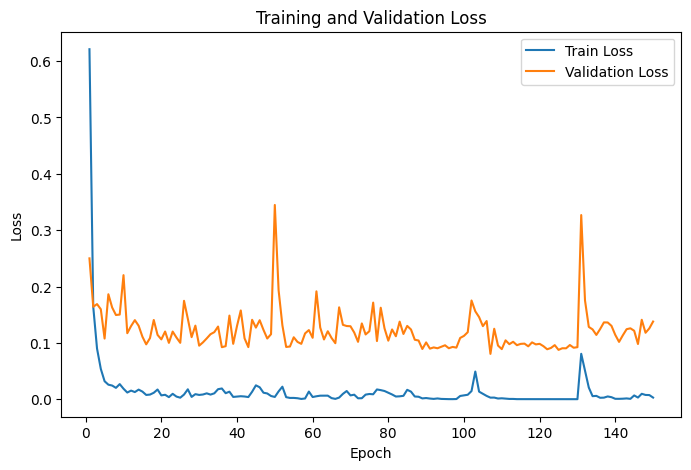

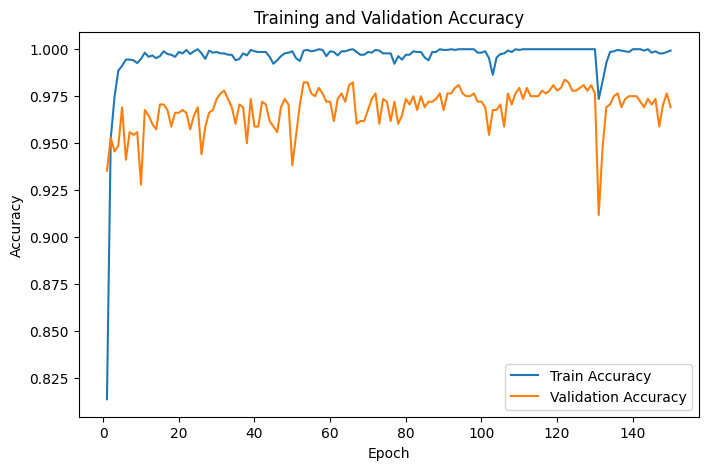

In [45]:
print ("Non letterbox")
plot_training_history(history_full_non_letterbox)


letterbox


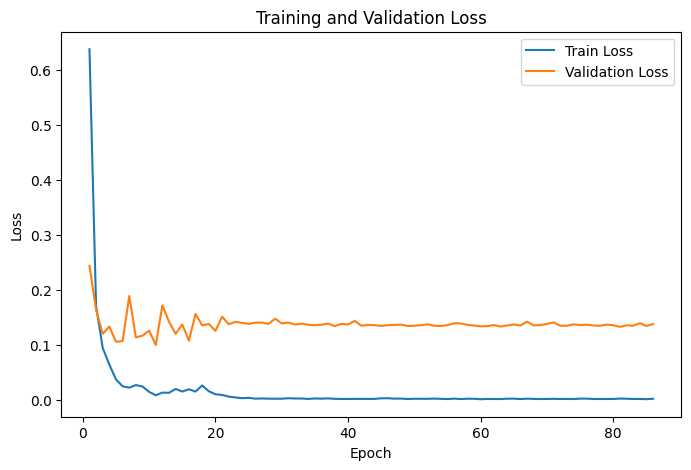

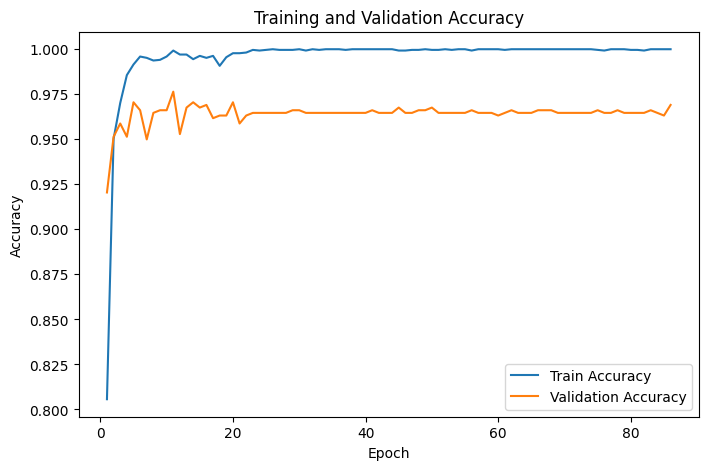

In [41]:
print ("letterbox")
plot_training_history(history_full_letterbox)

### Validation evaluation

              precision    recall  f1-score   support

   ambulance       0.99      1.00      0.99        71
     autobus       0.99      0.99      0.99        94
      kamyun       0.99      0.98      0.99       101
    kamyunet       0.98      0.98      0.98        91
     minibus       0.98      0.99      0.98        81
      savari       1.00      0.98      0.99       102
        taxi       0.99      0.98      0.98       100
       vanet       0.93      0.97      0.95        39

    accuracy                           0.98       679
   macro avg       0.98      0.98      0.98       679
weighted avg       0.98      0.98      0.98       679

{'ambulance': {'precision': 1.0, 'recall': 0.9861111111111112, 'f1-score': 0.993006993006993, 'support': 72.0}, 'autobus': {'precision': 0.9893617021276596, 'recall': 0.9893617021276596, 'f1-score': 0.9893617021276596, 'support': 94.0}, 'kamyun': {'precision': 0.9801980198019802, 'recall': 0.99, 'f1-score': 0.9850746268656716, 'support': 100.0}, '

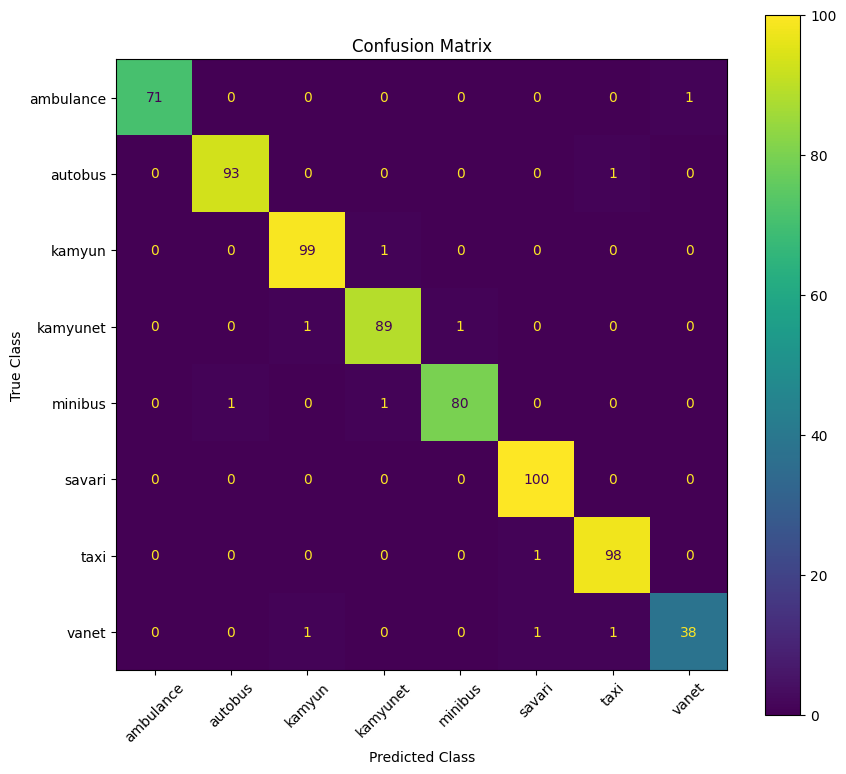

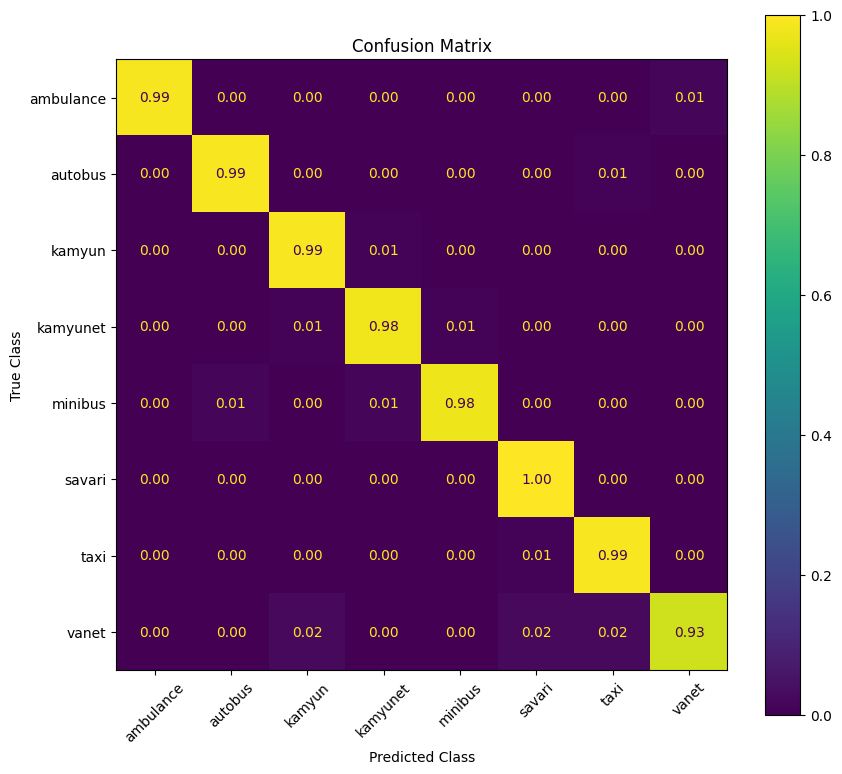

array([[0.98611111, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.01388889],
       [0.        , 0.9893617 , 0.        , 0.        , 0.        ,
        0.        , 0.0106383 , 0.        ],
       [0.        , 0.        , 0.99      , 0.01      , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.01098901, 0.97802198, 0.01098901,
        0.        , 0.        , 0.        ],
       [0.        , 0.01219512, 0.        , 0.01219512, 0.97560976,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        1.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.01010101, 0.98989899, 0.        ],
       [0.        , 0.        , 0.02439024, 0.        , 0.        ,
        0.02439024, 0.02439024, 0.92682927]])

In [46]:
val_preds, val_labels = get_predictions(resnet_full, val_loader, DEVICE)

print(classification_report(val_labels, val_preds, target_names=class_names))

report_full = get_classification_report(
    model=resnet_full,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    output_dict=True,
)

plot_confusion_matrix(resnet_full, val_loader, class_names, DEVICE)
plot_confusion_matrix(resnet_full, val_loader, class_names, DEVICE, normalize="true")


### Grad-CAM setup

Hooks into `layer4` (the last conv block before the global average pool) — the standard
Grad-CAM target for a ResNet.

In [47]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        output[:, class_idx].backward()

        pooled_grad = self.gradients.mean(dim=[0, 2, 3])
        activations = self.activations.squeeze(0).clone()
        for i in range(activations.shape[0]):
            activations[i] *= pooled_grad[i]

        heatmap = activations.mean(dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap = heatmap / (heatmap.max() + 1e-8)
        return heatmap, class_idx


def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()
    return img


def overlay_heatmap(image_np, heatmap, alpha=0.45):
    heatmap_img = Image.fromarray(np.uint8(heatmap * 255)).resize(
        (image_np.shape[1], image_np.shape[0]), resample=Image.BILINEAR
    )
    heatmap_colored = plt.cm.jet(np.array(heatmap_img) / 255.0)[..., :3]
    return (1 - alpha) * image_np + alpha * heatmap_colored


gradcam = GradCAM(resnet_full, resnet_full.layer4)


### Grad-CAM on misclassified validation images

Finds the first 8 or less validation samples the model got wrong and shows what it was
looking at when it made the mistake.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.000000011920929].


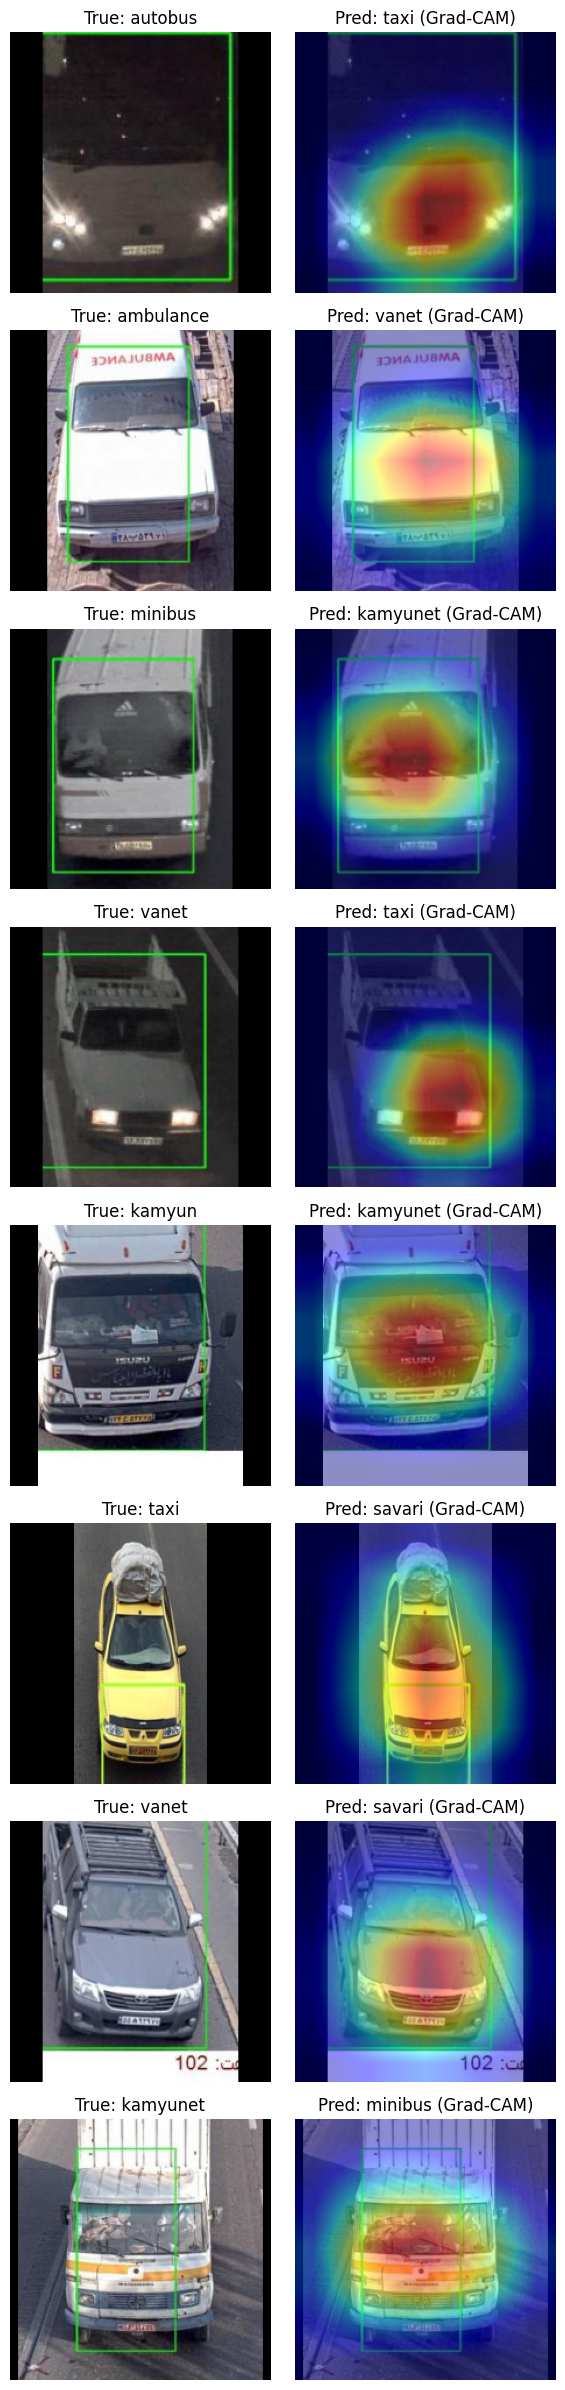

Total misclassified samples:  9
Showing 8 misclassified validation samples 


In [48]:
resnet_full.eval()

mistakes = []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = resnet_full(images)
        preds = outputs.argmax(dim=1)
        wrong_mask = preds != labels
        for i in torch.where(wrong_mask)[0]:
            mistakes.append((images[i].cpu(), labels[i].item(), preds[i].item()))
        if len(mistakes) >= 8:
            break

n_show = min(8, len(mistakes))
fig, axes = plt.subplots(n_show, 2, figsize=(6, 3 * n_show))
if n_show == 1:
    axes = axes.reshape(1, 2)

for row, (img_tensor, true_idx, pred_idx) in enumerate(mistakes[:n_show]):
    input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
    heatmap, _ = gradcam.generate(input_tensor, class_idx=pred_idx)

    img_np = denormalize(img_tensor)
    overlay = overlay_heatmap(img_np, heatmap)

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"True: {class_names[true_idx]}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"Pred: {class_names[pred_idx]} (Grad-CAM)")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

print ("Total misclassified samples: ",len(mistakes))
print(f"Showing {n_show} misclassified validation samples ")
